# Rollout evaluation: one-step prediction vs. sustained simulation

All numbers come from `eval/carla_eval.py`, `eval/carla_sensitivity.py` and `eval/tinyskies_eval.py`, run on the released ONNX models. Outputs live in `results/eval/`. Horizons are in model steps: CARLA runs at 20 Hz (1 step = 50 ms); TinySkies data averages about 7.5 fps (1 step ≈ 133 ms).

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from eval import plotstyle as ps

ps.apply()
FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)
pd.set_option("display.precision", 4)
E = Path('eval')
ROLE_ORDER = ['train', 'val', 'unseen']

## CARLA: replay against the real recording

Each rollout starts from a real recorded state, receives the recorded controls, and then consumes only its own predictions for 100 steps (5 s). `one step` feeds the true state at every step (the training-style metric). `copy` holds the seed frame. Recording roles: *train* (a world_v3 training recording), *val* (a held-out validation recording), *unseen* (recorded after training, with a different driving style).

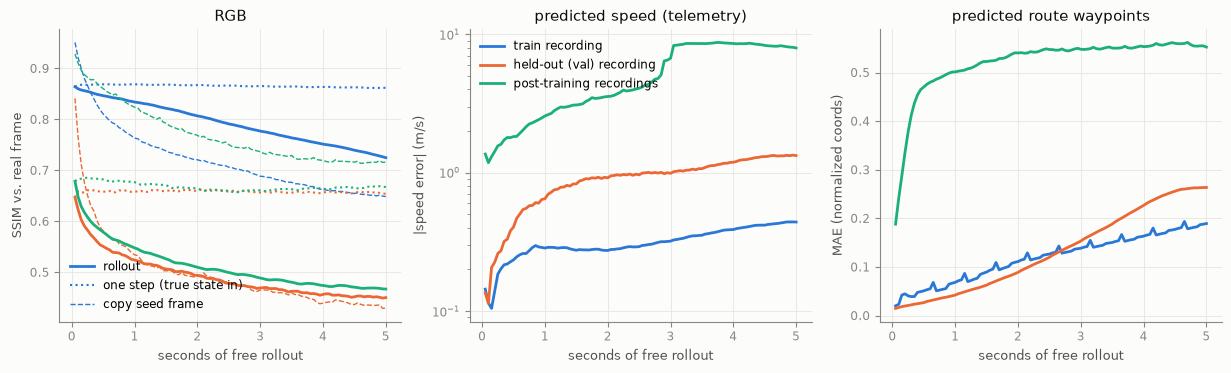

In [2]:
rep = pd.read_csv(E / "carla/replay.csv.gz")
rep["speed_abs_err"] = (rep.speed_pred_mps - rep.speed_true_mps).abs()
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for role in ROLE_ORDER:
    g = rep[rep.role == role].groupby("k").mean(numeric_only=True)
    c = ps.ROLE_COLORS[role]
    axes[0].plot(g.index / 20, g.rgb_ssim, color=c, label=f"{ps.ROLE_LABELS[role]}: rollout")
    axes[0].plot(g.index / 20, g.one_step_ssim, color=c, ls=":", lw=1.5, label="one step (true state in)")
    axes[0].plot(g.index / 20, g.copy_ssim, color=c, ls="--", lw=1, label="copy seed frame")
    axes[1].plot(g.index / 20, g.speed_abs_err, color=c, label=ps.ROLE_LABELS[role])
    axes[2].plot(g.index / 20, g.waypoints_mae, color=c, label=ps.ROLE_LABELS[role])
axes[0].set(xlabel="seconds of free rollout", ylabel="SSIM vs. real frame", title="RGB")
axes[1].set(xlabel="seconds of free rollout", ylabel="|speed error| (m/s)", title="predicted speed (telemetry)", yscale="log")
axes[2].set(xlabel="seconds of free rollout", ylabel="MAE (normalized coords)", title="predicted route waypoints")
handles, labels = axes[0].get_legend_handles_labels()
axes[0].legend(handles[:3], ["rollout", "one step (true state in)", "copy seed frame"], loc="lower left")
axes[1].legend(loc="upper left")
fig.savefig(FIGURES / "carla_replay.png")

In [3]:
rows = []
for role in ROLE_ORDER:
    for k in (1, 20, 100):
        d = rep[(rep.role == role) & (rep.k == k)]
        rows.append({"recording": role, "horizon": f"{k} ({k / 20:.2f} s)", "rollouts": d.start.nunique() * d.recording.nunique(),
                     "SSIM rollout": d.rgb_ssim.mean(), "SSIM one-step": d.one_step_ssim.mean(), "SSIM copy": d.copy_ssim.mean(),
                     "true speed (m/s)": d.speed_true_mps.mean(), "|speed err| (m/s)": d.speed_abs_err.mean(),
                     "waypoint MAE": d.waypoints_mae.mean(),
                     "sharpness pred / true": d.sharpness_pred.mean() / d.sharpness_true.mean()})
carla_table = pd.DataFrame(rows)
carla_table.to_csv(FIGURES / "carla_replay_table.csv", index=False)
carla_table

,recording,horizon,rollouts,SSIM rollout,SSIM one-step,SSIM copy,true speed (m/s),|speed err| (m/s),waypoint MAE,sharpness pred / true
0,train,1 (0.05 s),40,0.8641,0.8641,0.9511,3.2309,0.1441,0.0201,0.3073
1,train,20 (1.00 s),40,0.8340,0.8688,0.7632,3.2820,0.2854,0.0685,0.3017
2,train,100 (5.00 s),40,0.7249,0.8620,0.6487,3.2836,0.4402,0.1894,0.3329
3,val,1 (0.05 s),30,0.6470,0.6470,0.8413,7.1977,0.1352,0.0148,0.1155
4,val,20 (1.00 s),30,0.5242,0.6580,0.5343,7.2042,0.6482,0.0423,0.1032
5,val,100 (5.00 s),30,0.4504,0.6542,0.4298,5.6386,1.3284,0.2636,0.0977
6,unseen,1 (0.05 s),60,0.6786,0.6786,0.9284,0.9610,1.3630,0.1882,0.1052
7,unseen,20 (1.00 s),60,0.5478,0.6767,0.8239,0.8708,2.5689,0.5013,0.1495
8,unseen,100 (5.00 s),60,0.4671,0.6674,0.7163,0.8297,7.9622,0.5524,0.1738


### Turning vs. straight driving (all recordings, recorded |steer| > 0.1 at the step)

In [4]:
rep["turning"] = rep.steer.abs() > 0.1
turn = rep[rep.k.isin([10, 40, 100])].groupby(["k", "turning"])[["rgb_ssim", "speed_abs_err", "waypoints_mae"]].mean()
turn.to_csv(FIGURES / "carla_turning_table.csv")
turn

rgb_ssim  speed_abs_err  waypoints_mae
k   turning                                        
10  False      0.6574         0.8678         0.1929
    True       0.6474         1.3847         0.3639
40  False      0.6024         1.7650         0.2480
    True       0.5850         2.3756         0.4505
100 False      0.5552         1.8829         0.3176
    True       0.5109         9.7318         0.5159

## CARLA: which inputs does the model use?

Mean absolute change of each output when one input is taken from a different real frame (*shuffle*). The structured-state head never sees the image. The LiDAR latent barely moves the outputs; `eval/carla_lidar_probe.py` shows that it encodes scan information in a tiny range, but that this information is not propagated by the dynamics.

In [5]:
sens = json.loads((E / "carla/sensitivity.json").read_text())
shuffle = pd.DataFrame(sens["shuffle"]).T.rename(columns=lambda c: c.replace("next_", "Δ next "))
shuffle.index.name = "shuffled input"
shuffle.to_csv(FIGURES / "carla_sensitivity_table.csv")
display(shuffle)
probe = json.loads((E / "carla/lidar_probe.json").read_text())
pd.json_normalize(probe, sep=" / ").T.rename(columns={0: "value"})

,Δ next vision,Δ next lidar_latent,Δ next telemetry,Δ next waypoints
shuffled input,,,,
vision,1.0490e-01,0.0000,0.0000,0.0000
lidar_latent,1.7498e-05,0.0004,0.0003,0.0003
telemetry,2.7465e-03,0.0143,0.1160,0.0155
waypoints,1.0901e-02,0.0503,0.0811,0.2945
controls,7.4095e-03,0.0412,0.0569,0.0452


,value
frames,1.7000e+03
encoding / ridge_r2_occupied_cells / latent,8.0310e-01
encoding / ridge_r2_occupied_cells / raw_bev_pooled,8.9385e-01
encoding / ridge_r2_left_right_asymmetry / latent,7.6680e-01
encoding / ridge_r2_left_right_asymmetry / raw_bev_pooled,9.6481e-01
scale / input_mean_abs_diff_between_scans_over_mean_abs_scan,1.2906e+00
scale / latent_mean_abs_diff_between_scans_over_mean_abs_latent,1.7207e-03
scale / constant_predictor_mse (floor of the training LiDAR loss),8.1929e-06
scale / empty_scan_predictor_mse,8.1427e-05
propagation / one_step_error_in_latent_stds,2.3296e+03


## CARLA: action response and momentum

Scripted inputs from the six browser seeds (mean over seeds). Predicted speed is decoded from telemetry (channel 0 = tanh(v / 20 m/s)); the plot clips at 60 m/s. The training data rarely exceeds about 10 m/s.

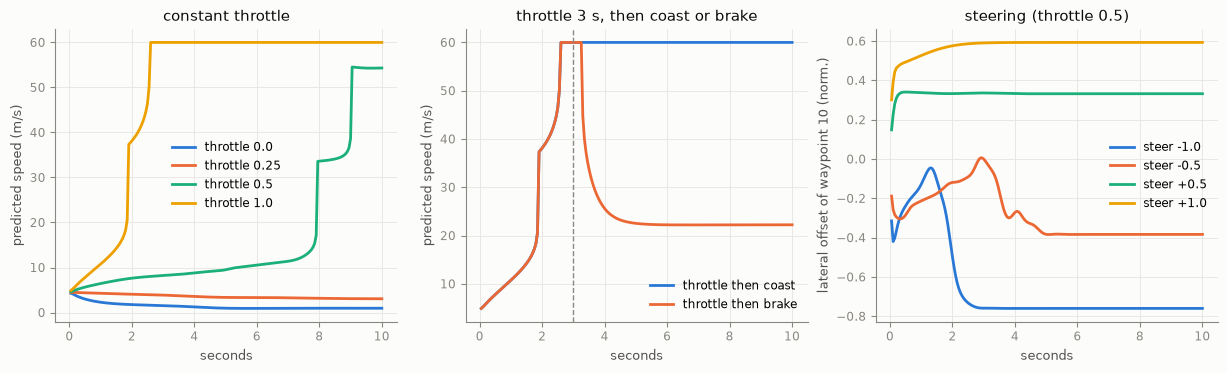

In [6]:
resp = pd.read_csv(E / "carla/action_response.csv.gz")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for level, c in zip((0.0, 0.25, 0.5, 1.0), ps.SERIES):
    g = resp[resp.condition == f"throttle_{level}"].groupby("k").speed_mps.mean()
    axes[0].plot(g.index / 20, g.clip(upper=60), color=c, label=f"throttle {level}")
for cond, c in (("throttle_then_coast", ps.BLUE), ("throttle_then_brake", ps.ORANGE)):
    g = resp[resp.condition == cond].groupby("k").speed_mps.mean()
    axes[1].plot(g.index / 20, g.clip(upper=60), color=c, label=cond.replace("_", " "))
axes[1].axvline(3, color=ps.MUTED, ls="--", lw=1)
for steer, c in zip((-1.0, -0.5, 0.5, 1.0), ps.SERIES):
    g = resp[resp.condition == f"steer_{steer}"].groupby("k").waypoint_lateral_10.mean()
    axes[2].plot(g.index / 20, g, color=c, label=f"steer {steer:+}")
axes[0].set(xlabel="seconds", ylabel="predicted speed (m/s)", title="constant throttle")
axes[1].set(xlabel="seconds", ylabel="predicted speed (m/s)", title="throttle 3 s, then coast or brake")
axes[2].set(xlabel="seconds", ylabel="lateral offset of waypoint 10 (norm.)", title="steering (throttle 0.5)")
for ax in axes: ax.legend()
fig.savefig(FIGURES / "carla_action_response.png")

## CARLA: long free-running rollouts (100 s)

Scripted constant inputs, real autopilot control sequences replayed open-loop (`recorded_controls`), and a simple controller that reads only the model's *predicted* speed and waypoints (`closed loop`). `frame change` is the mean absolute difference between consecutive frames: near zero means the image has frozen.

In [7]:
long = pd.read_csv(E / "carla/long_rollouts.csv.gz")
cl = pd.read_csv(E / "carla/closed_loop.csv.gz").assign(script=lambda d: "closed loop " + d.target_mps.astype(str) + " m/s")
both = pd.concat([long, cl], ignore_index=True)
summary = []
for script, d in both.groupby("script"):
    last = d[d.k > d.k.max() - 200]
    first_sat = d[d.telemetry_0 >= 0.999].groupby("seed").k.min() if "telemetry_0" in d else pd.Series(dtype=float)
    summary.append({"condition": script,
                    "speed at 100 s (m/s, median seed)": float(np.median(last.groupby("seed").speed_mps.mean())),
                    "seeds reaching speed ceiling": f"{first_sat.size}/{d.seed.nunique()}",
                    "median time to ceiling (s)": float(first_sat.median() / 20) if first_sat.size else np.nan,
                    "frame change, last 10 s": last.frame_change.mean(),
                    "seeds frozen (<1e-3), last 10 s": f"{(last.groupby('seed').frame_change.mean() < 1e-3).sum()}/{d.seed.nunique()}"})
long_table = pd.DataFrame(summary).set_index("condition")
long_table.to_csv(FIGURES / "carla_long_table.csv")
long_table

,"speed at 100 s (m/s, median seed)",seeds reaching speed ceiling,median time to ceiling (s),"frame change, last 10 s","seeds frozen (<1e-3), last 10 s"
condition,,,,,
closed loop 3.0 m/s,3.0186,0/6,NaN,1.3824e-03,5/6
closed loop 5.0 m/s,3.3625,0/6,NaN,4.5754e-04,6/6
closed loop 7.0 m/s,4.6023,0/6,NaN,9.7529e-05,6/6
cruise_0.5,5.0166,2/6,8.500,3.5927e-03,4/6
full_throttle,144.9546,6/6,2.750,7.8677e-03,0/6
idle,0.9518,0/6,NaN,5.3350e-04,5/6
left_0.5,144.9546,6/6,2.550,7.0571e-08,6/6
recorded_controls,2.2698,0/6,NaN,2.4421e-03,0/6
recorded_controls_fast_first,144.9547,4/6,4.775,7.6842e-03,0/6


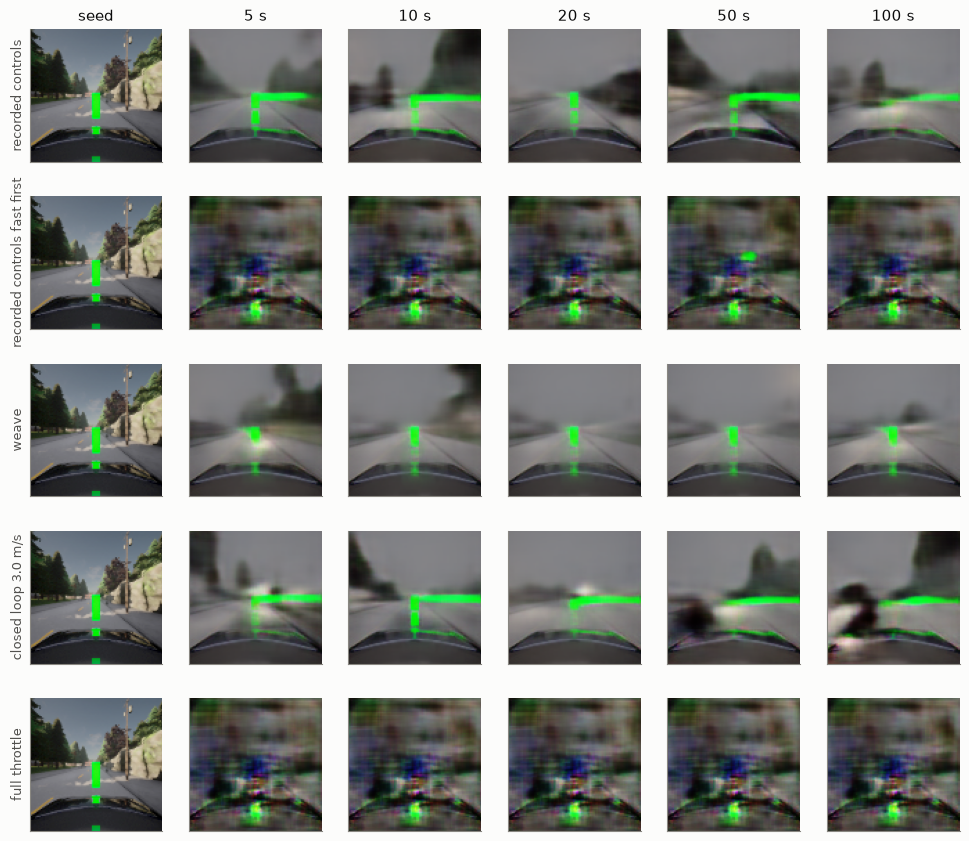

In [8]:
snap = {**np.load(E / "carla/long_rollout_snapshots.npz"),
        **{f"closed loop {k.split('_')[1]} m/s": v for k, v in np.load(E / "carla/closed_loop_snapshots.npz").items() if k != "snapshot_steps"}}
steps = list(snap.pop("snapshot_steps"))
show = ["recorded_controls", "recorded_controls_fast_first", "weave", "closed loop 3.0 m/s", "full_throttle"]
cols = [steps.index(k) for k in (0, 100, 200, 400, 1000, 2000)]  # step numbers; 100 steps = 5 s
seed = 2
fig, axes = plt.subplots(len(show), len(cols), figsize=(2 * len(cols), 2.1 * len(show)))
for r, name in enumerate(show):
    for c, j in enumerate(cols):
        ax = axes[r, c]; ax.imshow(snap[name][seed, j]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0: ax.set_title(f"{steps[j] // 20} s" if steps[j] else "seed")
        if c == 0: ax.set_ylabel(name.replace("_", " "), fontsize=9)
fig.savefig(FIGURES / "carla_long_snapshots.png")

## TinySkies: replay against the real session

Seeded with 4 real frames and their controls, then 64 steps of latent-only rollout under the recorded keys. `dyn` compares against the VAE reconstruction of the real frame, which removes reconstruction error and isolates dynamics error. The dashed line is the VAE ceiling (reconstruction of the real frame, no dynamics).

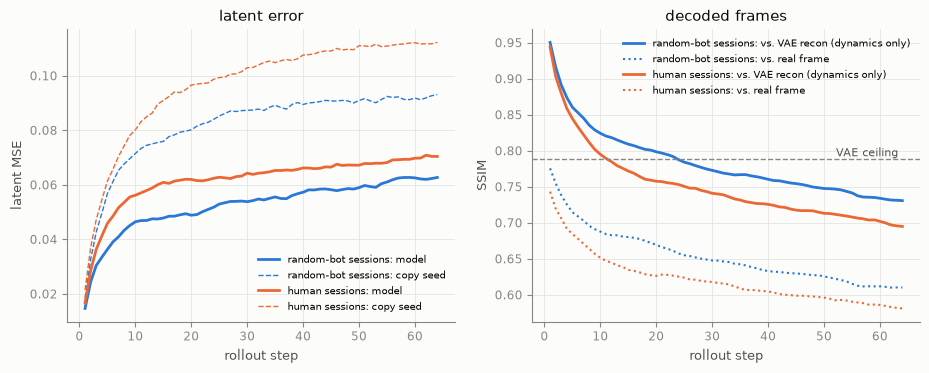

In [9]:
vae = pd.read_csv(E / "tinyskies/vae_ceiling.csv.gz")
tr = pd.read_csv(E / "tinyskies/replay.csv.gz")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for human, c, lab in ((False, ps.BLUE, "random-bot sessions"), (True, ps.ORANGE, "human sessions")):
    g = tr[tr.human == human].groupby("k").mean(numeric_only=True)
    axes[0].plot(g.index, g.latent_mse, color=c, label=f"{lab}: model")
    axes[0].plot(g.index, g.copy_latent_mse, color=c, ls="--", lw=1, label=f"{lab}: copy seed")
    axes[1].plot(g.index, g.dyn_ssim, color=c, label=f"{lab}: vs. VAE recon (dynamics only)")
    axes[1].plot(g.index, g.rgb_ssim, color=c, ls=":", lw=1.5, label=f"{lab}: vs. real frame")
axes[1].axhline(vae.ssim.mean(), color=ps.MUTED, ls="--", lw=1)
axes[1].text(64, vae.ssim.mean(), "VAE ceiling ", ha="right", va="bottom", fontsize=8, color=ps.INK_2)
axes[0].set(xlabel="rollout step", ylabel="latent MSE", title="latent error")
axes[1].set(xlabel="rollout step", ylabel="SSIM", title="decoded frames")
for ax in axes: ax.legend(fontsize=7.5)
fig.savefig(FIGURES / "tinyskies_replay.png")

In [10]:
rows = [{"horizon": "VAE ceiling", "SSIM vs real": vae.ssim.mean(), "PSNR": vae.psnr.mean(),
         "sharpness recon / true": vae.sharpness_recon.mean() / vae.sharpness_true.mean()}]
for k in (1, 8, 32, 64):
    d = tr[tr.k == k]
    rows.append({"horizon": f"{k}", "latent MSE": d.latent_mse.mean(), "latent MSE copy": d.copy_latent_mse.mean(),
                 "SSIM vs real": d.rgb_ssim.mean(), "SSIM vs recon (dynamics)": d.dyn_ssim.mean(),
                 "sharpness pred / true recon": d.sharpness_pred.mean() / d.sharpness_recon.mean()})
tiny_table = pd.DataFrame(rows)
tiny_table.to_csv(FIGURES / "tinyskies_replay_table.csv", index=False)
tiny_table

,horizon,SSIM vs real,PSNR,sharpness recon / true,latent MSE,latent MSE copy,SSIM vs recon (dynamics),sharpness pred / true recon
0,VAE ceiling,0.7887,26.8818,0.3533,NaN,NaN,NaN,NaN
1,1,0.7568,NaN,NaN,0.0158,0.0203,0.9467,0.9928
2,8,0.6772,NaN,NaN,0.0493,0.0716,0.8216,0.9639
3,32,0.6284,NaN,NaN,0.0603,0.0972,0.7514,0.9224
4,64,0.5933,NaN,NaN,0.0672,0.1043,0.7099,0.8977


## TinySkies: long free-running rollouts (2,000 steps from the 9 browser seeds)

,frame change (last 200),seeds frozen (<1e-3),sharpness (last 200),dist from seed
script,,,,
brake,8.4314e-05,9/9,0.0086,0.3598
forward,4.5101e-05,9/9,0.0083,0.3856
left,2.1986e-03,0/9,0.0086,0.3504
none,5.9628e-05,9/9,0.0087,0.3614
random_bot,7.3163e-04,9/9,0.0064,0.3507
right,2.1077e-03,1/9,0.0072,0.3354


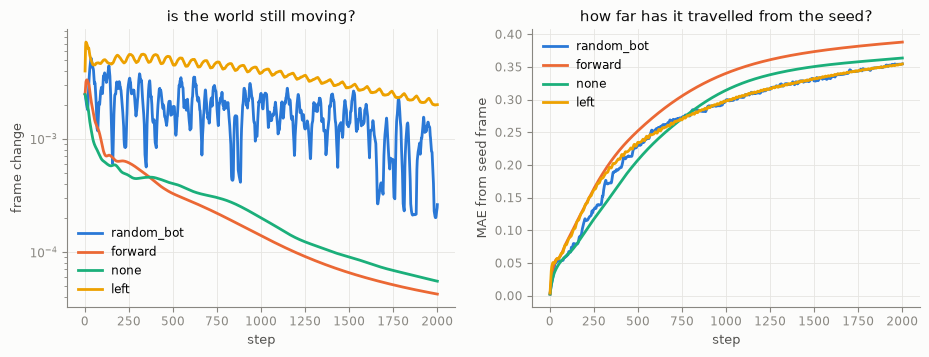

In [11]:
tl = pd.read_csv(E / "tinyskies/long_rollouts.csv.gz")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for (script, c) in zip(["random_bot", "forward", "none", "left"], ps.SERIES):
    g = tl[tl.script == script].groupby("k").mean(numeric_only=True)
    axes[0].plot(g.index, g.frame_change.rolling(20, min_periods=1).mean(), color=c, label=script)
    axes[1].plot(g.index, g.dist_from_seed, color=c, label=script)
axes[0].set(xlabel="step", ylabel="frame change", title="is the world still moving?", yscale="log")
axes[1].set(xlabel="step", ylabel="MAE from seed frame", title="how far has it travelled from the seed?")
for ax in axes: ax.legend()
fig.savefig(FIGURES / "tinyskies_long.png")
summary = []
for script, d in tl.groupby("script"):
    last = d[d.k > d.k.max() - 200]
    summary.append({"script": script, "frame change (last 200)": last.frame_change.mean(),
                    "seeds frozen (<1e-3)": f"{(last.groupby('seed').frame_change.mean() < 1e-3).sum()}/{d.seed.nunique()}",
                    "sharpness (last 200)": last.sharpness.mean(), "dist from seed": last.dist_from_seed.mean()})
tiny_long = pd.DataFrame(summary).set_index("script")
tiny_long.to_csv(FIGURES / "tinyskies_long_table.csv")
tiny_long

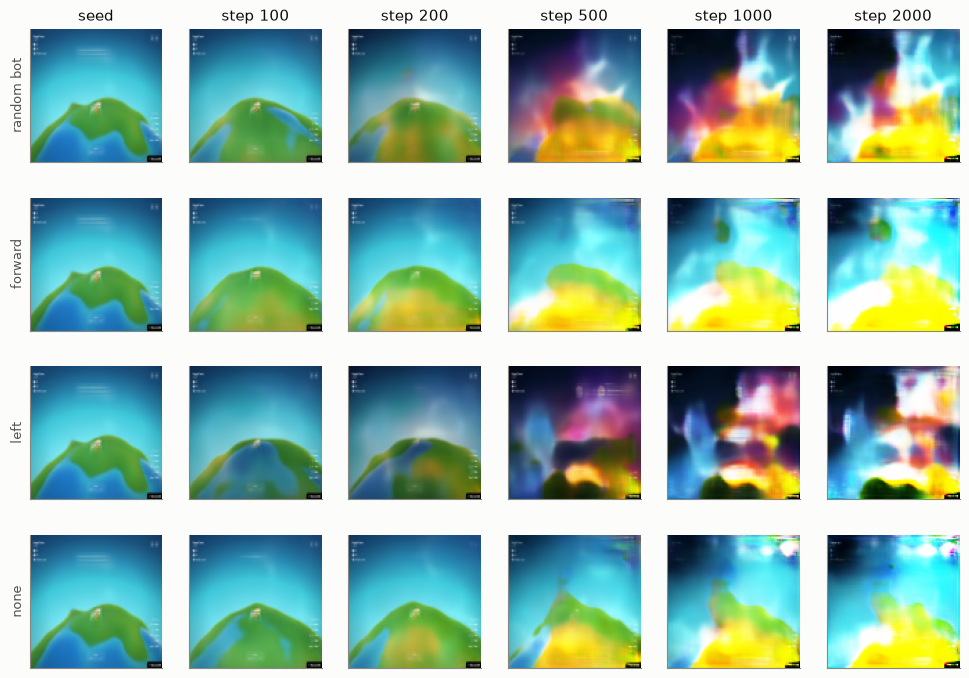

In [12]:
ts = dict(np.load(E / "tinyskies/long_rollout_snapshots.npz"))
steps = list(ts.pop("snapshot_steps"))
show, cols, seed = ["random_bot", "forward", "left", "none"], [steps.index(k) for k in (0, 100, 200, 500, 1000, 2000)], 0
fig, axes = plt.subplots(len(show), len(cols), figsize=(2 * len(cols), 2.1 * len(show)))
for r, name in enumerate(show):
    for c, j in enumerate(cols):
        ax = axes[r, c]; ax.imshow(ts[name][seed, j]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if r == 0: ax.set_title(f"step {steps[j]}" if steps[j] else "seed")
        if c == 0: ax.set_ylabel(name.replace("_", " "), fontsize=9)
fig.savefig(FIGURES / "tinyskies_long_snapshots.png")